### Fashion-MNIST UMAP 降维

流程：读取数据 → 分层抽样 7000 个样本（`SEED = 42`）→ 在另一份调参样本上扫描参数并选定 → UMAP 降维 → 保存结果。

`fashion-PCA.ipynb` 和 `fashion-UMAP.ipynb` 的数据读取、抽样和评估代码完全相同，两边降维用的是同一批样本，选参数用的也是同一批调参样本和同一套指标。

数据来源：Zalando Research 官方 idx 文件，首次运行会下载到 `dataset/`。

In [11]:
import gzip
import itertools
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.metrics import pairwise_distances, adjusted_rand_score, normalized_mutual_info_score
from sklearn.manifold import trustworthiness
import umap

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

SEED = 42
SAMPLE_RATIO = 0.1
TUNE_SEED = 0       # 调参样本的随机种子，与 SEED 不同

#### 1. 读取数据

训练集和测试集合并成 70000 个样本，每张图展平成 784 维，像素缩放到 [0, 1]。

In [12]:
DATA_DIR = Path('dataset')
DATA_DIR.mkdir(exist_ok=True)

BASE_URL = 'http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/'
FILES = ['train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz',
         't10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte.gz']
for fname in FILES:
    if not (DATA_DIR / fname).exists():
        print(f'下载 {fname} ...')
        urllib.request.urlretrieve(BASE_URL + fname, DATA_DIR / fname)

def load_images(path):
    # idx3 头部 16 字节：magic, 数量, 行数, 列数
    with gzip.open(path, 'rb') as f:
        return np.frombuffer(f.read(), dtype=np.uint8, offset=16).reshape(-1, 784)

def load_labels(path):
    # idx1 头部 8 字节：magic, 数量
    with gzip.open(path, 'rb') as f:
        return np.frombuffer(f.read(), dtype=np.uint8, offset=8)

X_full = np.concatenate([load_images(DATA_DIR / FILES[0]),
                         load_images(DATA_DIR / FILES[2])]).astype(np.float32) / 255.0
y_full = np.concatenate([load_labels(DATA_DIR / FILES[1]),
                         load_labels(DATA_DIR / FILES[3])])

CLASS_NAMES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print('X_full:', X_full.shape, ' y_full:', y_full.shape)

X_full: (70000, 784)  y_full: (70000,)


#### 2. 分层抽样 1/10

在 70000 个样本上整体分层抽样 10%，每类 700 张，共 7000 张。`random_state` 固定，每次抽到的样本相同。

In [13]:
sample_idx, _ = train_test_split(
    np.arange(len(y_full)),
    train_size=SAMPLE_RATIO,
    stratify=y_full,
    random_state=SEED,
)
sample_idx = np.sort(sample_idx)

X = X_full[sample_idx]
y = y_full[sample_idx]

print('X:', X.shape, ' y:', y.shape)
print('前 10 个抽中的索引:', sample_idx[:10])
print('每类数量:', np.bincount(y).tolist())

X: (7000, 784)  y: (7000,)
前 10 个抽中的索引: [13 21 22 25 40 50 60 68 86 93]
每类数量: [700, 700, 700, 700, 700, 700, 700, 700, 700, 700]


#### 3. 选择降维参数

参数不能在 SEED=42 这批评估样本上参考真实标签来挑，否则后面在这批样本上算 ARI、NMI 时等于提前看过答案。所以从剩下的 63000 个样本里再分层抽一份 7000 个样本（`TUNE_SEED = 0`，与评估样本不重叠），只在这份调参样本上扫描参数。

In [14]:
rest_idx = np.setdiff1d(np.arange(len(y_full)), sample_idx)
tune_idx, _ = train_test_split(
    rest_idx,
    train_size=len(sample_idx),
    stratify=y_full[rest_idx],
    random_state=TUNE_SEED,
)
tune_idx = np.sort(tune_idx)
assert len(np.intersect1d(tune_idx, sample_idx)) == 0

X_tune = X_full[tune_idx]
y_tune = y_full[tune_idx]

print('X_tune:', X_tune.shape, ' 与评估样本重叠:', len(np.intersect1d(tune_idx, sample_idx)))
print('每类数量:', np.bincount(y_tune).tolist())

X_tune: (7000, 784)  与评估样本重叠: 0
每类数量: [700, 700, 700, 700, 700, 700, 700, 700, 700, 700]


##### 3.1 评估指标与选择规则

每个参数配置在调参样本上降维后计算以下指标：

| 指标 | 计算方式 | 反映什么 |
|---|---|---|
| `ari`、`nmi` | 降维结果上跑 KMeans（k=10，`n_init=10`），与真实类别比较 | 聚类和真实类别的吻合程度 |
| `score` | `(ari + nmi) / 2` | **选参数的依据** |
| `knn_acc` | 降维结果上 10 近邻分类器的 5 折交叉验证准确率 | 类别信息保留了多少，不依赖聚类算法 |
| `trust` | trustworthiness（k=10）：降维后的近邻在原空间中是否也是近邻，1 为完全保留 | 局部结构保留了多少，不用标签 |

选择规则：`score` 与最高值相差不超过 `TOL = 0.01` 的配置算作并列最好，其中取维数最小的，维数相同再取 `score` 最高的。KMeans 结果受初始化影响，0.01 以内的差距说明不了好坏，这时维数少的更简单、聚类也更快。`knn_acc` 和 `trust` 不参与选择，用来确认选中的配置在其他方面没有明显变差。

sklearn 的 `trustworthiness` 每次都重算 7000×7000 的距离矩阵和排名，内存占用约 1 GB。这里先把原空间的近邻排名算一次，之后每个配置只算降维空间的近邻，公式与 sklearn 相同，下面在 2000 个样本上和 sklearn 的结果核对。

In [15]:
TOL = 0.01
K_TRUST = 10

def original_ranks(X, chunk=1000):
    # ranks[i, j]：原空间中 j 是 i 的第几近邻（自身为 0）
    n = len(X)
    ranks = np.empty((n, n), dtype=np.int32)
    for s in range(0, n, chunk):
        d = pairwise_distances(X[s:s + chunk], X)
        d[np.arange(len(d)), np.arange(s, s + len(d))] = -1   # 自身排在最前
        order = np.argsort(d, axis=1)
        np.put_along_axis(ranks[s:s + chunk], order, np.arange(n, dtype=np.int32)[None, :], axis=1)
    return ranks

def trust_score(ranks, E, k=K_TRUST):
    # 与 sklearn.manifold.trustworthiness 的公式相同
    n = len(E)
    nbr = NearestNeighbors(n_neighbors=k).fit(E).kneighbors(return_distance=False)
    r = np.take_along_axis(ranks, nbr, axis=1) - k
    return 1 - 2.0 / (n * k * (2 * n - 3 * k - 1)) * r[r > 0].sum()

def evaluate(E, y, ranks):
    pred = KMeans(n_clusters=10, n_init=10, random_state=SEED).fit_predict(E)
    ari = adjusted_rand_score(y, pred)
    nmi = normalized_mutual_info_score(y, pred)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    knn_acc = cross_val_score(KNeighborsClassifier(n_neighbors=10), E, y, cv=cv).mean()
    return dict(score=(ari + nmi) / 2, ari=ari, nmi=nmi, knn_acc=knn_acc, trust=trust_score(ranks, E))

def pick(df, dim_col='n_components'):
    # score 在最高值 TOL 以内的配置里，取维数最小的，再取 score 最高的
    tied = df[df['score'] >= df['score'].max() - TOL]
    return tied.sort_values([dim_col, 'score'], ascending=[True, False]).iloc[0], tied

METRIC_COLS = ['score', 'ari', 'nmi', 'knn_acc', 'trust']
METRIC_FMT = {c: '{:.3f}' for c in METRIC_COLS}

ranks_tune = original_ranks(X_tune)

# 和 sklearn 核对（取 2000 个样本、每隔 8 个像素取一列当作"降维结果"）
X_chk, E_chk = X_tune[:2000], X_tune[:2000, ::8]
print(f'trust_score: {trust_score(original_ranks(X_chk), E_chk):.6f}')
print(f'sklearn    : {trustworthiness(X_chk, E_chk, n_neighbors=K_TRUST):.6f}')

trust_score: 0.989180
sklearn    : 0.989180


##### 3.2 扫描 UMAP 参数

UMAP 要定的参数：

- `n_neighbors`：构图时看多少个近邻。小了偏重局部结构，容易把一类拆成几块；大了偏重全局结构，相近的类容易并在一起。
- `min_dist`：降维后点之间允许的最小距离。越小同类点挤得越紧，聚类越容易分开；越大点分布越均匀，适合看结构。
- `n_components`：降到几维。
- `metric`：原空间用什么距离。图像常用欧氏距离和余弦距离。

全组合共 4×2×4×2 = 64 个配置。每个配置单线程拟合约 12 秒（固定 `random_state` 时 UMAP 只能单线程），全部跑完约 15 分钟。结果存到 `result/umap-param-sweep.csv`，重新运行时如果配置没变就直接读文件。

In [16]:
UMAP_GRID = dict(n_neighbors=[10, 15, 30, 50], min_dist=[0.0, 0.1],
                 n_components=[2, 5, 10, 20], metric=['euclidean', 'cosine'])
GRID_KEYS = list(UMAP_GRID)

def as_params(row):
    # 从 DataFrame 行取出参数，转成 UMAP 能接受的 Python 类型
    return dict(n_neighbors=int(row['n_neighbors']), min_dist=float(row['min_dist']),
                n_components=int(row['n_components']), metric=str(row['metric']))

def run_umap_configs(configs, seeds, cache_file):
    # configs: 参数字典列表；每个配置按每个 seed 拟合一次。缓存与当前配置完全一致时直接读取
    want = {(*(c[k] for k in GRID_KEYS), s) for c in configs for s in seeds}
    if cache_file.exists():
        cached = pd.read_csv(cache_file)
        have = {(*(as_params(r)[k] for k in GRID_KEYS), int(r['seed'])) for _, r in cached.iterrows()}
        if have == want:
            print('读取缓存:', cache_file)
            return cached
    rows, t0 = [], time.time()
    for i, (c, s) in enumerate(itertools.product(configs, seeds), 1):
        E = umap.UMAP(**c, random_state=s, n_jobs=1).fit_transform(X_tune)
        rows.append(dict(**c, seed=s, **evaluate(E, y_tune, ranks_tune)))
        print(f'[{i}/{len(want)}] {c} seed={s} score={rows[-1]["score"]:.3f}  {time.time() - t0:.0f}s', flush=True)
    df = pd.DataFrame(rows)
    df.to_csv(cache_file, index=False)
    print('已保存:', cache_file)
    return df

grid_configs = [dict(zip(GRID_KEYS, v)) for v in itertools.product(*UMAP_GRID.values())]
umap_sweep = run_umap_configs(grid_configs, [SEED], Path('result') / 'umap-param-sweep.csv')

读取缓存: result\umap-param-sweep.csv


##### 3.3 扫描结果

表 1 是全部 64 个配置的 `score`：行是 `n_neighbors` 和 `min_dist`，列是 `metric` 和 `n_components`，颜色越深越好。

In [17]:
(umap_sweep.pivot_table(index=['n_neighbors', 'min_dist'], columns=['metric', 'n_components'], values='score')
   .style.format('{:.3f}').background_gradient(cmap='Greens', axis=None)
   .set_caption('表 1  UMAP 参数扫描 score = (ARI + NMI) / 2（调参样本，seed=42）'))

表 2 是每个参数单独看的平均效果：固定一个参数的取值，对其余参数的所有组合取 `score` 平均。用来看哪个参数影响最大、往哪个方向调更好。

In [18]:
main_effects = pd.concat(
    [umap_sweep.groupby(k)[METRIC_COLS].mean().reset_index().rename(columns={k: '取值'}).assign(参数=k)
     for k in GRID_KEYS]
).set_index(['参数', '取值'])
main_effects.style.format(METRIC_FMT).background_gradient(cmap='Greens').set_caption('表 2  各参数的平均效果')

表 3 是 `score` 最高的 10 个配置，同时列出各项指标。

In [19]:
(umap_sweep.sort_values('score', ascending=False).head(10).drop(columns='seed')
   .style.format(METRIC_FMT).background_gradient(subset=METRIC_COLS, cmap='Greens')
   .set_caption('表 3  score 前 10 的配置'))

,n_neighbors,min_dist,n_components,metric,score,ari,nmi,knn_acc,trust
27,15,0.100000,5,cosine,0.555,0.476,0.634,0.793,0.924
47,30,0.100000,20,cosine,0.555,0.476,0.634,0.787,0.923
43,30,0.100000,5,cosine,0.554,0.475,0.634,0.784,0.922
15,10,0.100000,20,cosine,0.554,0.476,0.632,0.794,0.927
45,30,0.100000,10,cosine,0.554,0.475,0.633,0.785,0.923
61,50,0.100000,10,cosine,0.554,0.475,0.633,0.780,0.921
63,50,0.100000,20,cosine,0.554,0.475,0.632,0.782,0.922
51,50,0.000000,5,cosine,0.553,0.475,0.632,0.776,0.919
59,50,0.100000,5,cosine,0.553,0.475,0.632,0.778,0.921
25,15,0.100000,2,cosine,0.553,0.474,0.632,0.766,0.912


##### 3.4 随机种子稳定性

UMAP 结果受随机种子影响，上面只用了 seed=42，排名靠前的配置之间的差距可能只是随机波动。把前 5 名配置各用 5 个种子重新拟合，按平均 `score` 选择。

In [20]:
TOP_K = 5
STABILITY_SEEDS = [0, 1, 2, 3, SEED]

top_configs = [as_params(r) for _, r in umap_sweep.sort_values('score', ascending=False).head(TOP_K).iterrows()]
stab_raw = run_umap_configs(top_configs, STABILITY_SEEDS, Path('result') / 'umap-param-stability.csv')

stab = stab_raw.groupby(GRID_KEYS)[METRIC_COLS].agg(['mean', 'std'])
stab.columns = [f'{m}_{s}' for m, s in stab.columns]
stab = stab.rename(columns={'score_mean': 'score'}).reset_index().sort_values('score', ascending=False)

(stab.style.format({c: '{:.3f}' for c in stab.columns if c not in GRID_KEYS})
   .background_gradient(subset=['score'], cmap='Greens')
   .set_caption(f'表 4  前 {TOP_K} 名配置在 {len(STABILITY_SEEDS)} 个种子上的均值和标准差'))

读取缓存: result\umap-param-stability.csv


,n_neighbors,min_dist,n_components,metric,score,score_std,ari_mean,ari_std,nmi_mean,nmi_std,knn_acc_mean,knn_acc_std,trust_mean,trust_std
3,30,0.100000,10,cosine,0.554,0.000,0.475,0.000,0.633,0.000,0.786,0.001,0.923,0.001
4,30,0.100000,20,cosine,0.554,0.000,0.475,0.000,0.633,0.001,0.787,0.002,0.923,0.000
2,30,0.100000,5,cosine,0.554,0.001,0.475,0.000,0.633,0.001,0.785,0.001,0.922,0.000
1,15,0.100000,5,cosine,0.553,0.006,0.470,0.015,0.636,0.003,0.792,0.001,0.925,0.000
0,10,0.100000,20,cosine,0.550,0.007,0.464,0.018,0.636,0.004,0.795,0.003,0.927,0.000


##### 3.5 按规则选定参数

在表 4 的平均 `score` 上应用 3.1 的选择规则。

In [21]:
best_umap, tied_umap = pick(stab)
UMAP_PARAMS = dict(as_params(best_umap), random_state=SEED, n_jobs=1)

display(tied_umap.style.format({c: '{:.3f}' for c in stab.columns if c not in GRID_KEYS})
        .set_caption(f'表 5  平均 score ≥ {stab["score"].max():.3f} - {TOL} 的配置'))
print('选定:', as_params(best_umap))
print(f'  平均 score={best_umap["score"]:.3f} ± {best_umap["score_std"]:.3f}')

,n_neighbors,min_dist,n_components,metric,score,score_std,ari_mean,ari_std,nmi_mean,nmi_std,knn_acc_mean,knn_acc_std,trust_mean,trust_std
3,30,0.100000,10,cosine,0.554,0.000,0.475,0.000,0.633,0.000,0.786,0.001,0.923,0.001
4,30,0.100000,20,cosine,0.554,0.000,0.475,0.000,0.633,0.001,0.787,0.002,0.923,0.000
2,30,0.100000,5,cosine,0.554,0.001,0.475,0.000,0.633,0.001,0.785,0.001,0.922,0.000
1,15,0.100000,5,cosine,0.553,0.006,0.470,0.015,0.636,0.003,0.792,0.001,0.925,0.000
0,10,0.100000,20,cosine,0.550,0.007,0.464,0.018,0.636,0.004,0.795,0.003,0.927,0.000


选定: {'n_neighbors': 30, 'min_dist': 0.1, 'n_components': 5, 'metric': 'cosine'}
  平均 score=0.554 ± 0.001


#### 4. UMAP 降维

像素已在 [0, 1]，量纲一致，不再额外标准化。用第 3 节选定的 `UMAP_PARAMS` 在评估样本上拟合，结果用于聚类。`random_state` 固定后结果可复现。

UMAP 高维结果取前 2 列没有意义，所以用同样的 `n_neighbors`、`min_dist`、`metric` 另外拟合一个 2 维 UMAP 专门画图；如果选定的维数本身就是 2，直接复用。

In [22]:
X_red = umap.UMAP(**UMAP_PARAMS).fit_transform(X)
if UMAP_PARAMS['n_components'] == 2:
    X_red_2d = X_red
else:
    X_red_2d = umap.UMAP(**{**UMAP_PARAMS, 'n_components': 2}).fit_transform(X)

print('降维后:', X_red.shape, ' 画图用:', X_red_2d.shape)

降维后: (7000, 5)  画图用: (7000, 2)


#### 5. 保存结果

结果保存在变量 `fashion_umap_redu_result`（字典）中，同时写入 `result/fashion-umap-redu-result.npz`。后续聚类直接读文件，不用重跑降维：

```python
r = np.load('result/fashion-umap-redu-result.npz')
X, y = r['embedding'], r['labels']
```

| 键 | 内容 |
|---|---|
| `embedding` | (7000, UMAP_PARAMS['n_components']) 降维结果，聚类用 |
| `embedding_2d` | (7000, 2)，画图用 |
| `labels` | 真实类别（整数），只用于 ARI、NMI 等外部指标，聚类时不能用 |
| `class_names` | 类别名，下标对应 `labels` |
| `sample_idx` | 在 70000 个原始样本中的索引，PCA 与 UMAP 两份结果应完全相同 |
| `n_neighbors`、`min_dist`、`n_components`、`metric` | 第 3 节选定的 UMAP 参数 |
| `seed` | 随机种子 |
| `tune_idx` | 调参样本在 70000 个原始样本中的索引，PCA 与 UMAP 两份结果应完全相同 |

In [13]:
fashion_umap_redu_result = {
    'embedding': X_red.astype(np.float32),
    'embedding_2d': X_red_2d.astype(np.float32),
    'labels': y,
    'class_names': np.array(CLASS_NAMES),
    'sample_idx': sample_idx,
    'n_neighbors': UMAP_PARAMS['n_neighbors'],
    'min_dist': UMAP_PARAMS['min_dist'],
    'n_components': UMAP_PARAMS['n_components'],
    'metric': UMAP_PARAMS['metric'],
    'seed': SEED,
    'tune_idx': tune_idx,
}

RESULT_FILE = Path('result') / 'fashion-umap-redu-result.npz'
RESULT_FILE.parent.mkdir(exist_ok=True)
np.savez(RESULT_FILE, **fashion_umap_redu_result)

# 读回来逐项核对
with np.load(RESULT_FILE) as saved:
    assert all(np.array_equal(saved[k], v) for k, v in fashion_umap_redu_result.items())
print('已保存并校验:', RESULT_FILE)
for k, v in fashion_umap_redu_result.items():
    print(f'  {k}: shape={np.shape(v)}, dtype={np.asarray(v).dtype}')

已保存并校验: result\fashion-umap-redu-result.npz
  embedding: shape=(7000, 5), dtype=float32
  embedding_2d: shape=(7000, 2), dtype=float32
  labels: shape=(7000,), dtype=uint8
  class_names: shape=(10,), dtype=<U11
  sample_idx: shape=(7000,), dtype=int64
  n_neighbors: shape=(), dtype=int64
  min_dist: shape=(), dtype=float64
  n_components: shape=(), dtype=int64
  metric: shape=(), dtype=<U6
  seed: shape=(), dtype=int64
  tune_idx: shape=(7000,), dtype=int64


#### 6. 可视化检查

二维结果按真实类别着色，只用来确认降维结果正常。

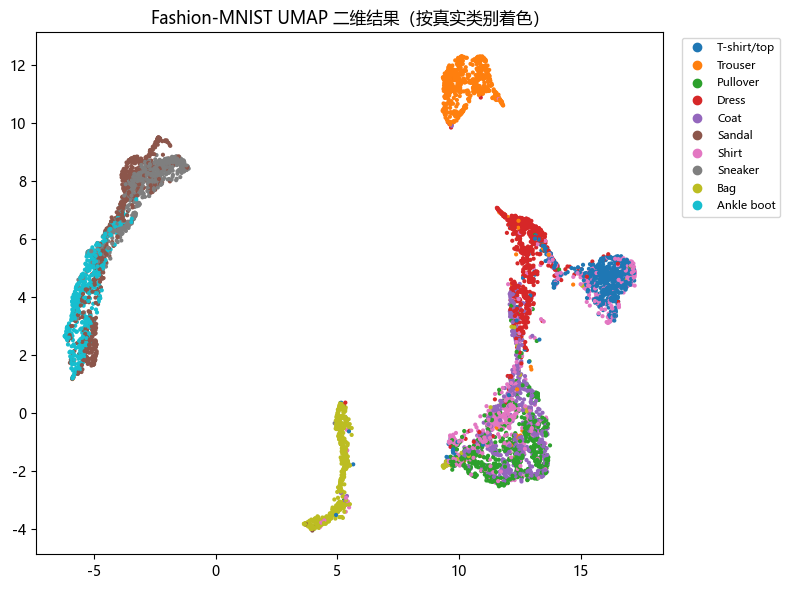

In [14]:
emb2 = fashion_umap_redu_result['embedding_2d']
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(emb2[:, 0], emb2[:, 1], c=y, cmap='tab10', s=4)
ax.legend(sc.legend_elements()[0], CLASS_NAMES, fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
ax.set_title('Fashion-MNIST UMAP 二维结果（按真实类别着色）')
plt.tight_layout()
plt.show()